# Pokemon Test
https://www.youtube.com/watch?v=LLBGiAAZqAM

In [62]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [34]:
# LLM-assisted (Claude, 2026-11-24): download pokemon.csv once and load it with pandas.

data = pd.read_csv("pokemon.csv")
data1 = data.query("`Type 1`.isin(('Electric', 'Grass'))")
data1


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
30,25,Pikachu,Electric,NaN,320,35,55,40,50,50,90,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
740,672,Skiddo,Grass,NaN,350,66,65,48,62,57,52,6,False
741,673,Gogoat,Grass,NaN,531,123,100,62,97,81,68,6,False
764,694,Helioptile,Electric,Normal,289,44,38,33,61,43,70,6,False
765,695,Heliolisk,Electric,Normal,481,62,55,52,109,94,109,6,False


Classification problem:
Electric or grass

In [35]:
# Training data
X = data1[['HP', 'Attack', 'Defense', 'Speed', ]] # Features
y = (data1['Type 1'] == 'Electric') # = 0 if Grass, = 1 if Electric


In [48]:
# Picks the feature split which gives the highest accuracy
tree = DecisionTreeClassifier(max_depth=2).fit(X, y)
tree.classes_

array([False,  True])

[Text(0.5, 0.8333333333333334, 'x[3] <= 85.5\ngini = 0.474\nsamples = 114\nvalue = [70, 44]'),
 Text(0.25, 0.5, 'x[2] <= 34.5\ngini = 0.354\nsamples = 74\nvalue = [57, 17]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.32\nsamples = 5\nvalue = [1, 4]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.306\nsamples = 69\nvalue = [56, 13]'),
 Text(0.75, 0.5, 'x[0] <= 90.5\ngini = 0.439\nsamples = 40\nvalue = [13, 27]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.394\nsamples = 37\nvalue = [10, 27]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]')]

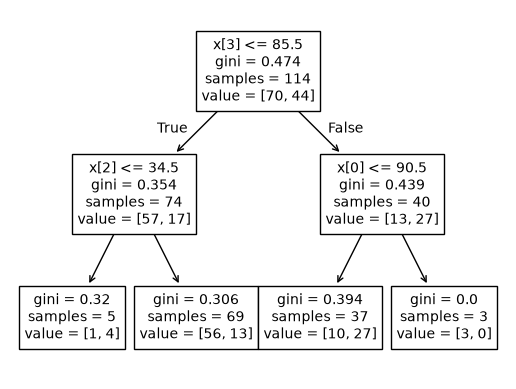

In [49]:
plot_tree(tree)

Picks the features and the values at which to split the data for True
and False qualification.
X[3] = 'Speed' the chosen feature for the first split.
X[2] = 'Defense'  
X[0] = 'HP'

In [ ]:
# Training Data prediction
predictions = tree.predict(X) 
predictions
acc = accuracy_score(y, tree.predict(X))
print(f"{acc:%}")

78.947368%


^Overfitting: It memorizes the training data instead of learning
the underlying patterns.

In [ ]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
md = 1
tree = DecisionTreeClassifier(max_depth=md).fit(X_train, y_train)

In [55]:
acc_train = accuracy_score(y_train,tree.predict(X_train))
acc_test = accuracy_score(y_test,tree.predict(X_test))
print(f"Training accuracy: {acc_train:%}")
print(f"Test accuracy: {acc_test:%}")

Training accuracy: 83.516484%
Test accuracy: 56.521739%


In [63]:
acc_train_l = []
acc_test_l = []
md_l = np.array(range(1,10))
for max_depth in md_l:
    tree_i = DecisionTreeClassifier(max_depth=max_depth).fit(X_train, y_train)
    acc_train_l.append(accuracy_score(y_train,tree_i.predict(X_train)))
    acc_test_l.append(accuracy_score(y_test,tree_i.predict(X_test)))

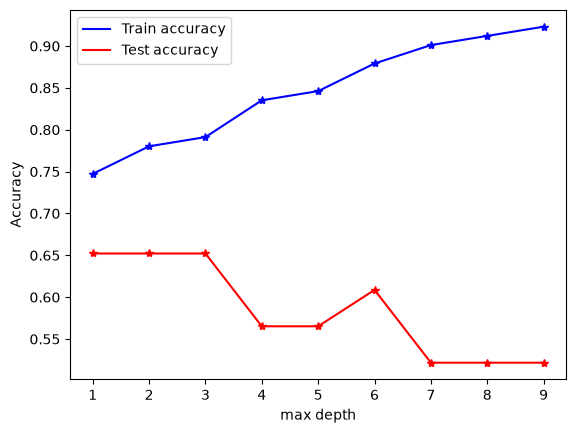

In [67]:
plt.plot(md_l, acc_train_l, color = "blue", label = "Train accuracy")
plt.plot(md_l, acc_train_l, "*", color = "blue")
plt.plot(md_l, acc_test_l, color = "red", label = "Test accuracy")
plt.plot(md_l, acc_test_l, "*", color = "red")
plt.legend()
plt.xlabel("max depth")
plt.ylabel("Accuracy")
plt.show()

Mitigation:  
Limit depth of tree.  
--> Pruning (Post processing) - cut out unimportant parts.  
--> Random forest